# Ejercicio 1. Descenso de gradiente matricial
**Objetivo:** desarrollar la función cuadrática, verificar su gradiente, clasificar el punto crítico y calcular tres iteraciones.

Se utiliza $x=(x_1,x_2)^T$, $\gamma=0.15$ y $x^{(0)}=(0,0)^T$.

In [1]:
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sp.init_printing()
x1, x2 = sp.symbols("x_1 x_2", real=True)
x = sp.Matrix([x1,x2])
A = sp.Matrix([[4,0],[0,10]])
b = sp.Matrix([-8,10])
gamma = 0.15

## 1. Desarrollo del producto matricial
$$Ax=(4x_1,10x_2)^T$$
$$x^TAx=4x_1^2+10x_2^2,\quad b^Tx=-8x_1+10x_2$$
$$f(x)=2x_1^2+5x_2^2+8x_1-10x_2$$

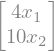

In [2]:
display(A*x, x.T*A*x, b.T*x)
f = sp.expand((sp.Rational(1,2)*x.T*A*x-b.T*x)[0])
display(f)

## 2. Gradiente matricial y analítico
Como $A=A^T$, el gradiente columna es $Ax-b$.
$$\frac{\partial f}{\partial x_1}=4x_1+8,\quad \frac{\partial f}{\partial x_2}=10x_2-10$$
Se verifica la igualdad de ambos métodos.

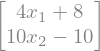

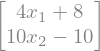

Los gradientes coinciden: True


In [3]:
g_mat = A*x-b
g_ana = sp.Matrix([sp.diff(f,v) for v in x])
display(g_mat,g_ana)
assert g_mat == g_ana
print("Los gradientes coinciden:", g_mat == g_ana)

## 3. Raíces del gradiente
$$4x_1+8=0\Rightarrow x_1=-2$$
$$10x_2-10=0\Rightarrow x_2=1$$
El único punto crítico es $(-2,1)^T$.

In [4]:
sol = sp.solve(list(g_ana), [x1,x2])
display(sol)
print("Valor de la función en el punto crítico:", f.subs(sol))

Valor de la función en el punto crítico: -13


## 4. Clasificación mediante segundas derivadas
$$f_{x_1x_1}=4,\quad f_{x_2x_2}=10,\quad f_{x_1x_2}=f_{x_2x_1}=0$$
$$H=\begin{pmatrix}4&0\\0&10\end{pmatrix},\quad D=40>0$$
Como $f_{x_1x_1}>0$ y la Hessiana es definida positiva en todo el dominio, existe un mínimo global único, con valor $-13$.

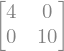

Derivadas cruzadas: 0 0
Determinante: 40
Valores propios: {4: 1, 10: 1}
Clasificación: mínimo global


In [5]:
H = sp.hessian(f, (x1,x2))
display(H)
print("Derivadas cruzadas:", H[0,1], H[1,0])
print("Determinante:", H.det())
print("Valores propios:", H.eigenvals())
print("Clasificación: mínimo global" if H.is_positive_definite else "Revisar clasificación")

## 5. Descenso de gradiente
Se emplea $x^{(i+1)}=x^{(i)}-\gamma g(x^{(i)})$, donde $g$ es el gradiente columna. Esto equivale a transponer el gradiente fila de la regla del enunciado.

$$x^{(1)}=(0,0)^T-0.15(8,-10)^T=(-1.2,1.5)^T$$
$$x^{(2)}=(-1.2,1.5)^T-0.15(3.2,5)^T=(-1.68,0.75)^T$$
$$x^{(3)}=(-1.68,0.75)^T-0.15(1.28,-2.5)^T=(-1.872,1.125)^T$$

In [6]:
A_np = np.array(A, dtype=float)
b_np = np.array(b, dtype=float).ravel()
def funcion(v):
    return 0.5*(v @ A_np @ v)-b_np @ v
def gradiente(v):
    return A_np @ v-b_np
v = np.zeros(2)
filas = []
trayectoria = []
for i in range(4):
    g = gradiente(v)
    trayectoria.append(v.copy())
    filas.append({"Iteración": i, "x^(i)": tuple(map(float,np.round(v,6))), "Gradiente": tuple(map(float,np.round(g,6))), "f(x^(i))": round(funcion(v),6)})
    if i < 3:
        siguiente = v-gamma*g
        print(f"x^({i+1}) = {v} - {gamma} * {g} = {siguiente}")
        v = siguiente
tabla = pd.DataFrame(filas)
display(tabla)

x^(1) = [0. 0.] - 0.15 * [  8. -10.] = [-1.2  1.5]
x^(2) = [-1.2  1.5] - 0.15 * [3.2 5. ] = [-1.68  0.75]
x^(3) = [-1.68  0.75] - 0.15 * [ 1.28 -2.5 ] = [-1.872  1.125]


,Iteración,x^(i),Gradiente,f(x^(i))
0,0,"(0.0, 0.0)","(8.0, -10.0)",0.000000
1,1,"(-1.2, 1.5)","(3.2, 5.0)",-10.470000
2,2,"(-1.68, 0.75)","(1.28, -2.5)",-12.482700
3,3,"(-1.872, 1.125)","(0.512, 1.25)",-12.889107


## Visualización de la convergencia (complementaria)

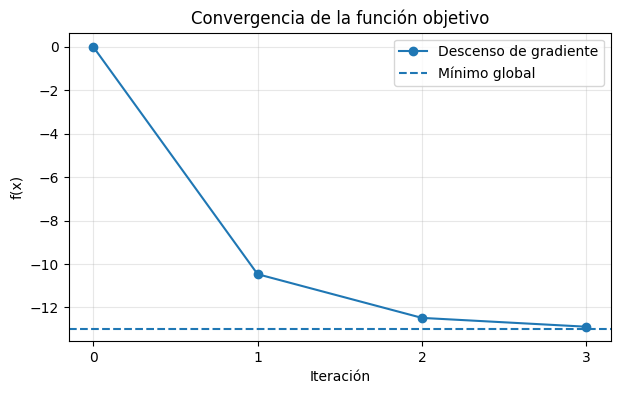

In [7]:
plt.figure(figsize=(7,4))
plt.plot(tabla["Iteración"], tabla["f(x^(i))"], "o-", label="Descenso de gradiente")
plt.axhline(-13, linestyle="--", label="Mínimo global")
plt.xticks(range(4))
plt.xlabel("Iteración")
plt.ylabel("f(x)")
plt.title("Convergencia de la función objetivo")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Conclusión
Los gradientes matricial y analítico coinciden. La Hessiana definida positiva confirma el mínimo global en (-2, 1). Tras tres iteraciones, el valor de la función es -12.889107, cercano al mínimo de -13, sin alcanzarlo exactamente.